## imports

In [57]:
# import os
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import time
from pathlib import Path
from collections import Counter
import cv2
from sklearn.model_selection import train_test_split    


## check valide syntax
## and classes balance

In [58]:
valide_extentions = ['.jpeg', '.jpg', '.bmp', '.png']
result = []
classes = []
imgCount_class = {}

for folder in Path('../Data').iterdir():
    if folder.is_dir():
        extensions = Counter(
            file.suffix.lower()
            for file in folder.iterdir()
            if file.is_file()
        )
        files_count = sum(
            1 for file in folder.iterdir() 
            if file.is_file()
        )

    f = {'folder' : folder.name, 'extensions' : extensions}
    result.append(f)
    classes.append(folder.name)
    imgCount_class[folder.name] = files_count


print(imgCount_class)
print(classes)

{'glioma': 1621, 'meningioma': 1645, 'notumor': 2000, 'pituitary': 1757}
['glioma', 'meningioma', 'notumor', 'pituitary']


## list&labels

In [59]:
labels = []
images = []
valide_extentions = ['.jpg', '.jpeg', '.bmp', '.png']
path = Path('../Data')

classes = sorted([folder.name for folder in path.iterdir() if folder.is_dir()])

for label, class_name in enumerate(classes):
    folder = path / class_name
    for file in folder.iterdir():
        if file.suffix.lower() in valide_extentions:
            img = cv2.imread(file)
            if img is None:
                print('image didn t load. it will be skipped!')
                continue

            img = cv2.resize(img, (224, 224))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            images.append(img)
            labels.append(label)

print(len(images))
print(len(labels))

y = np.array(labels)
X = np.array(images)

assert len(y) == len(X), 'mismatsh between images and lables length!'   
# print(enumerate(classes))

7023
7023


In [60]:
# verify data shape
print(X.shape[:])
print(y.shape[:])
X.dtype

(7023, 224, 224, 3)
(7023,)


dtype('uint8')

## visualisation

Text(0, 0.5, 'imgaes count')

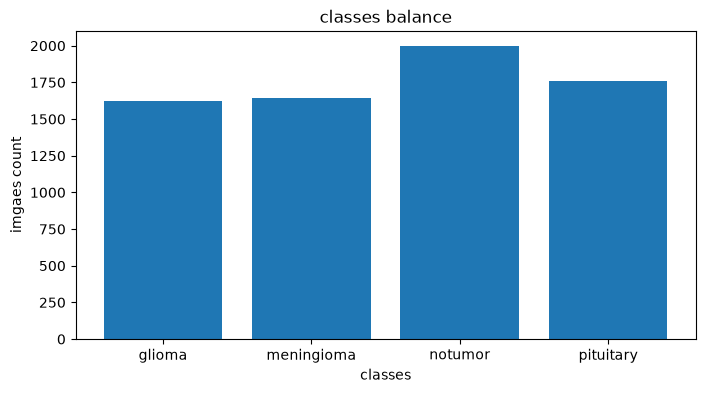

In [61]:
plt.figure(figsize=(8, 4))
plt.bar(imgCount_class.keys(), imgCount_class.values())
plt.title('classes balance')
plt.xlabel('classes')
plt.ylabel('imgaes count')

## split test/train data

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2 ,random_state=42)


# split the training set into training/validations sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, 
    y_train,
    random_state=42,
    stratify=y_train,
    test_size=0.15
)
print(X_train.shape)
print(X_test.shape)



(5618, 224, 224, 3)
(1405, 224, 224, 3)


## normalisation des pixcel


In [64]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train.max()
X_test.max()
X_train.min()
X_test.min()

MemoryError: Unable to allocate 3.15 GiB for an array with shape (5618, 224, 224, 3) and data type float32

In [ ]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(256, (3, 3), activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.5),
    # tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')  # 4 classes for your tumor dataset
])

print(model.summary())

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
EPOCHS = 20
BATCH_SIZE = 32


checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_model.h5',
    monitor = 'val_accuracy',
    save_best_only = True
)

start = time.time()
end = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs = EPOCHS,
    batch_size = BATCH_SIZE,
    validation_data = (X_val, y_val),
    callbacks = [checkpoint]
)
end = time.time()
print(f'Training time: {end - start:.2f}s')


In [ ]:
# evaluation
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")


In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True)